In [1]:
# Install OCR and evaluation dependencies
# Install system-level Tesseract OCR

!apt-get update -qq
!apt-get install -y -qq tesseract-ocr
!apt-get install -y -qq tesseract-ocr-eng
!apt-get install -y -qq tesseract-ocr-hin
!apt-get install -y -qq tesseract-ocr-kan

# Install Python dependencies

%pip install -q easyocr jiwer pytesseract opencv-python-headless pillow pandas numpy tqdm matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-hin.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-hin_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-hin (1:4.1.0-2) ...
Setting up tesseract-ocr-hin (1:4.1.0-2) ...
Selecting previously unselected package tesseract-ocr-kan.
(Reading database ... 122817 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-kan_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-kan (1:4.1.0-2) ...
Setting up tesseract-ocr-kan (1:4.1.0-2) ...


In [2]:
import os
import sys
import json
import gc
import time
import warnings
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import easyocr
import jiwer
import pytesseract

from PIL import Image
from tqdm.auto import tqdm
from jiwer import cer, wer

print("All imports completed successfully!")

All imports completed successfully!


In [3]:
import easyocr
import torch
import jiwer
import pytesseract
import cv2
import pandas as pd
import importlib.metadata

from jiwer import cer, wer
from PIL import Image
from tqdm.auto import tqdm

print("EasyOCR:", easyocr.__version__)
print("PyTorch:", torch.__version__)
print("JiWER:", importlib.metadata.version("jiwer"))
print("OpenCV:", cv2.__version__)
print("Pandas:", pd.__version__)
print("Tesseract:", pytesseract.get_tesseract_version())

print("\nTesseract languages:")
print(pytesseract.get_languages(config=""))

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nAll dependencies verified successfully!")

EasyOCR: 1.7.2
PyTorch: 2.14.1+cpu
JiWER: 4.0.0
OpenCV: 5.0.0
Pandas: 2.2.3
Tesseract: 5.3.4

Tesseract languages:
['eng', 'hin', 'kan', 'osd']

GPU available: False

All dependencies verified successfully!


In [5]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [6]:
PROJECT_ROOT = "/content/drive/MyDrive/BharatDocAI"

# Dataset paths
ANNOTATION_PATH = os.path.join(
    PROJECT_ROOT,
    "data/annotations/synthetic_documents.jsonl"
)

MANIFEST_PATH = os.path.join(
    PROJECT_ROOT,
    "data/processed/degradation_manifest.csv"
)

RAW_DOCUMENT_DIR = os.path.join(
    PROJECT_ROOT,
    "data/raw_documents"
)

DEGRADED_DOCUMENT_DIR = os.path.join(
    PROJECT_ROOT,
    "data/processed/degraded"
)

# Existing Tesseract results
TESSERACT_DIR = os.path.join(
    PROJECT_ROOT,
    "data/ocr_outputs/tesseract"
)

TESSERACT_CLEAN_PATH = os.path.join(
    TESSERACT_DIR,
    "tesseract_clean_results.jsonl"
)

TESSERACT_DEGRADED_PATH = os.path.join(
    TESSERACT_DIR,
    "tesseract_degraded_results.jsonl"
)

# New EasyOCR results
EASYOCR_DIR = os.path.join(
    PROJECT_ROOT,
    "data/ocr_outputs/easyocr"
)

EASYOCR_RESULTS_PATH = os.path.join(
    EASYOCR_DIR,
    "easyocr_all_results.jsonl"
)

# New PaddleOCR results
PADDLEOCR_DIR = os.path.join(
    PROJECT_ROOT,
    "data/ocr_outputs/paddleocr"
)

PADDLEOCR_RESULTS_PATH = os.path.join(
    PADDLEOCR_DIR,
    "paddleocr_all_results.jsonl"
)

# Metrics and reports
METRICS_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs/metrics"
)

VISUALIZATION_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs/visualizations"
)

os.makedirs(EASYOCR_DIR, exist_ok=True)
os.makedirs(PADDLEOCR_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)
os.makedirs(VISUALIZATION_DIR, exist_ok=True)

print("Project paths configured!")
print("Project root:", PROJECT_ROOT)

Project paths configured!
Project root: /content/drive/MyDrive/BharatDocAI


In [7]:
required_files = {
    "Annotations": ANNOTATION_PATH,
    "Degradation manifest": MANIFEST_PATH,
    "Tesseract clean results": TESSERACT_CLEAN_PATH,
    "Tesseract degraded results": TESSERACT_DEGRADED_PATH
}

for name, path in required_files.items():

    status = "FOUND" if os.path.exists(path) else "MISSING"

    print(f"{name}: {status}")

    if status == "MISSING":
        print("  Expected path:", path)

Annotations: FOUND
Degradation manifest: FOUND
Tesseract clean results: FOUND
Tesseract degraded results: FOUND


In [8]:
# Load annotations
with open(ANNOTATION_PATH, "r", encoding="utf-8") as f:

    annotations = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

# Load degradation manifest
manifest_df = pd.read_csv(MANIFEST_PATH)

# Ground truth mapping
ground_truth = {
    item["document_id"]: item["document_text"]
    for item in annotations
}

print("Annotations:", len(annotations))
print("Manifest records:", len(manifest_df))
print("Ground truth documents:", len(ground_truth))

print("\nManifest columns:")
print(manifest_df.columns.tolist())

print("\nCorruption counts:")
print(manifest_df["corruption"].value_counts())

print("\nSeverity counts:")
print(manifest_df["severity"].value_counts())

assert len(annotations) == 90
assert len(manifest_df) == 1440
assert len(ground_truth) == 90

print("\nDataset successfully loaded!")

Annotations: 90
Manifest records: 1440
Ground truth documents: 90

Manifest columns:
['document_id', 'language', 'category', 'template_family', 'split', 'corruption', 'severity', 'parameter', 'image_path']

Corruption counts:
corruption
gaussian_blur       270
gaussian_noise      270
low_contrast        270
rotation            270
jpeg_compression    270
clean                90
Name: count, dtype: int64

Severity counts:
severity
mild        450
moderate    450
severe      450
none         90
Name: count, dtype: int64

Dataset successfully loaded!


In [9]:
def resolve_image_path(value):

    path = str(value)

    if os.path.exists(path):
        return path

    raise FileNotFoundError(
        f"Image not found: {path}"
    )


def normalize_text(text):

    text = unicodedata.normalize("NFC", str(text))

    return " ".join(text.split())


def evaluate_ocr_text(reference, hypothesis):

    reference = normalize_text(reference)
    hypothesis = normalize_text(hypothesis)

    document_cer = cer(reference, hypothesis)
    document_wer = wer(reference, hypothesis)

    return {
        "CER": document_cer,
        "WER": document_wer,
        "character_accuracy": 1 - document_cer
    }


def load_jsonl(path):

    if not os.path.exists(path):
        return []

    with open(path, "r", encoding="utf-8") as f:

        return [
            json.loads(line)
            for line in f
            if line.strip()
        ]


def save_jsonl(records, path):

    with open(path, "w", encoding="utf-8") as f:

        for record in records:

            f.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )


print("Helper functions ready!")

Helper functions ready!


In [10]:
tesseract_clean_results = load_jsonl(
    TESSERACT_CLEAN_PATH
)

tesseract_degraded_results = load_jsonl(
    TESSERACT_DEGRADED_PATH
)

print("Tesseract clean records:", len(tesseract_clean_results))
print("Tesseract degraded records:", len(tesseract_degraded_results))

print(
    "Clean successful:",
    sum(x.get("status") == "success" for x in tesseract_clean_results)
)

print(
    "Degraded successful:",
    sum(x.get("status") == "success" for x in tesseract_degraded_results)
)

Tesseract clean records: 90
Tesseract degraded records: 1350
Clean successful: 90
Degraded successful: 1350


In [11]:
# Full dataset
ocr_dataset = manifest_df.copy()

# Sort consistently
ocr_dataset = ocr_dataset.sort_values(
    by=["language", "document_id", "corruption", "severity"]
).reset_index(drop=True)

print("Total OCR images:", len(ocr_dataset))

print("\nLanguage distribution:")
print(ocr_dataset["language"].value_counts())

print("\nSplit distribution:")
print(ocr_dataset["split"].value_counts())

print("\nCorruption distribution:")
print(ocr_dataset["corruption"].value_counts())

assert len(ocr_dataset) == 1440

print("\nCommon OCR dataset ready!")

Total OCR images: 1440

Language distribution:
language
english    480
hindi      480
kannada    480
Name: count, dtype: int64

Split distribution:
split
train         864
validation    288
test          288
Name: count, dtype: int64

Corruption distribution:
corruption
gaussian_blur       270
gaussian_noise      270
low_contrast        270
jpeg_compression    270
rotation            270
clean                90
Name: count, dtype: int64

Common OCR dataset ready!


In [12]:
EASYOCR_LANGUAGES = {
    "english": ["en"],
    "hindi": ["hi", "en"],
    "kannada": ["kn", "en"]
}

def create_easyocr_reader(language):

    return easyocr.Reader(
        EASYOCR_LANGUAGES[language],
        gpu=torch.cuda.is_available(),
        verbose=False
    )


print("EasyOCR configuration ready!")

EasyOCR configuration ready!


In [13]:
print("Available languages:")
print(manifest_df["language"].unique())

print("\nAvailable corruption values:")
print(manifest_df["corruption"].unique())

print("\nFirst 15 clean documents:")
display(
    manifest_df[
        manifest_df["corruption"].astype(str).str.lower() == "clean"
    ][[
        "document_id",
        "language",
        "category",
        "corruption",
        "image_path"
    ]].head(15)
)

Available languages:
['english' 'hindi' 'kannada']

Available corruption values:
['clean' 'gaussian_blur' 'gaussian_noise' 'rotation' 'low_contrast'
 'jpeg_compression']

First 15 clean documents:


,document_id,language,category,corruption,image_path
0,english_invoice_001,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
16,english_invoice_002,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
32,english_invoice_003,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
48,english_invoice_004,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
64,english_invoice_005,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
80,english_invoice_006,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
96,english_invoice_007,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
112,english_invoice_008,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
128,english_invoice_009,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...
144,english_invoice_010,english,invoice,clean,/content/drive/MyDrive/BharatDocAI/data/raw_do...


In [14]:
sample_rows = (
    manifest_df[
        manifest_df["corruption"].astype(str).str.lower() == "clean"
    ]
    .sort_values("document_id")
    .groupby("language", as_index=False)
    .first()
)

print("Selected sample documents:")
display(sample_rows[[
    "document_id",
    "language",
    "image_path"
]])

print("\nSamples found:", len(sample_rows))

Selected sample documents:


,document_id,language,image_path
0,english_application_011,english,/content/drive/MyDrive/BharatDocAI/data/raw_do...
1,hindi_application_041,hindi,/content/drive/MyDrive/BharatDocAI/data/raw_do...
2,kannada_application_071,kannada,/content/drive/MyDrive/BharatDocAI/data/raw_do...



Samples found: 3


In [15]:
for _, row in sample_rows.iterrows():

    language = str(row["language"]).lower()

    print("\n" + "=" * 60)
    print("LANGUAGE:", language)
    print("DOCUMENT:", row["document_id"])

    reader = create_easyocr_reader(language)

    image_path = resolve_image_path(row["image_path"])

    output = reader.readtext(
        image_path,
        detail=0,
        paragraph=False
    )

    extracted_text = "\n".join(output)

    print("\nGROUND TRUTH:")
    print(ground_truth[row["document_id"]])

    print("\nEASYOCR OUTPUT:")
    print(extracted_text)

    del reader
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


LANGUAGE: english
DOCUMENT: english_application_011


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



GROUND TRUTH:
APPLICATION FORM
Applicant Name: Sneha Nair
Application Date: 11/01/2026
Application ID: APP-0011
Address: Bengaluru
Phone Number: 9000001507

EASYOCR OUTPUT:
APPLICATION FORM
Applicant Name:
Sneha Nair
Application Date:
11/01/2026
Application ID:
APP-0011
Address:
Bengaluru
Phone Number:
9000001507

LANGUAGE: hindi
DOCUMENT: hindi_application_041


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



GROUND TRUTH:
आवेदन पत्र
आवेदक का नाम: विक्रम जोशी
आवेदन दिनांक: 10/02/2026
आवेदन संख्या: APP-0041
पता: बेंगलुरु
फोन नंबर: 9000005617

EASYOCR OUTPUT:
आवेदन पत्र
आवेदक का नामः
विक्रम जोशी
आवेदन दिनांकः
10/02/2026
आवेदन संख्याः
APP-0041
पता
फोन नंबरः
9000005617
बेंगलुरु



LANGUAGE: kannada
DOCUMENT: kannada_application_071


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



GROUND TRUTH:
ಅರ್ಜಿ ನಮೂನೆ
ಅರ್ಜಿದಾರರ ಹೆಸರು: ಅರ್ಜುನ್ ನಾಯರ್
ಅರ್ಜಿ ದಿನಾಂಕ: 12/03/2026
ಅರ್ಜಿ ಸಂಖ್ಯೆ: APP-0071
ವಿಳಾಸ: ಬೆಂಗಳೂರು
ದೂರವಾಣಿ ಸಂಖ್ಯೆ: 9000009727

EASYOCR OUTPUT:
ಅರ್ಜಿ ನಮೂನೆ
ಅರ್ಜಿದಾರರ ಹೆಸರು:
ಅರ್ಜುನ್ ನಾಯರ್
ಅರ್ಜಿ ದಿನಾಂಕ:
12 |03 | 2026
ಅರ್ಜಿ
ಸಂಖ್ಯೆ :
APP-0071
ವಿಳಾಸ:
ಬೆಂಗಳೂರು
ದೂರವಾಣಿ ಸಂಖ್ಯೆ:
9000009727


In [16]:
def run_easyocr(reader, image_path):

    results = reader.readtext(
        image_path,
        detail=0,
        paragraph=False
    )

    return "\n".join(results).strip()

In [17]:
def run_easyocr(reader, image_path):

    results = reader.readtext(
        image_path,
        detail=0,
        paragraph=False
    )

    return "\n".join(results).strip()


print("EasyOCR processing function ready!")

EasyOCR processing function ready!


In [18]:

# Load existing results for resume support

existing_results = load_jsonl(EASYOCR_RESULTS_PATH)

processed_keys = {
    (
        x["document_id"],
        x["corruption"],
        x["severity"]
    )
    for x in existing_results
    if x.get("status") == "success"
}

print("Previously completed:", len(processed_keys))

with open(
    EASYOCR_RESULTS_PATH,
    "a",
    encoding="utf-8"
) as output_file:

    for language in ["english", "hindi", "kannada"]:

        print(f"\nProcessing language: {language}")

        reader = create_easyocr_reader(language)

        language_df = ocr_dataset[
            ocr_dataset["language"] == language
        ]

        for _, row in tqdm(
            language_df.iterrows(),
            total=len(language_df),
            desc=f"EasyOCR {language}"
        ):

            doc_id = str(row["document_id"])
            corruption = str(row["corruption"])
            severity = str(row["severity"])

            key = (doc_id, corruption, severity)

            if key in processed_keys:
                continue

            try:

                image_path = resolve_image_path(
                    row["image_path"]
                )

                extracted_text = run_easyocr(
                    reader,
                    image_path
                )

                result = {
                    "engine": "easyocr",
                    "document_id": doc_id,
                    "language": language,
                    "category": row["category"],
                    "split": row["split"],
                    "corruption": corruption,
                    "severity": severity,
                    "parameter": float(row["parameter"]),
                    "image_path": image_path,
                    "ground_truth": ground_truth[doc_id],
                    "ocr_text": extracted_text,
                    "status": "success"
                }

            except Exception as e:

                result = {
                    "engine": "easyocr",
                    "document_id": doc_id,
                    "language": language,
                    "corruption": corruption,
                    "severity": severity,
                    "status": "error",
                    "error": str(e)
                }

            output_file.write(
                json.dumps(
                    result,
                    ensure_ascii=False
                ) + "\n"
            )

            output_file.flush()

        del reader
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("\nEasyOCR processing completed!")
print("Saved to:", EASYOCR_RESULTS_PATH)

Previously completed: 1440

Processing language: english


EasyOCR english:   0%|          | 0/480 [00:00<?, ?it/s]


Processing language: hindi


EasyOCR hindi:   0%|          | 0/480 [00:00<?, ?it/s]


Processing language: kannada


EasyOCR kannada:   0%|          | 0/480 [00:00<?, ?it/s]


EasyOCR processing completed!
Saved to: /content/drive/MyDrive/BharatDocAI/data/ocr_outputs/easyocr/easyocr_all_results.jsonl


In [19]:
easyocr_results = load_jsonl(
    EASYOCR_RESULTS_PATH
)

easyocr_success = [
    x for x in easyocr_results
    if x.get("status") == "success"
]

easyocr_failed = [
    x for x in easyocr_results
    if x.get("status") != "success"
]

print("Total records:", len(easyocr_results))
print("Successful:", len(easyocr_success))
print("Failed:", len(easyocr_failed))

print("\nSuccessful records by language:")

print(
    pd.Series([
        x["language"]
        for x in easyocr_success
    ]).value_counts()
)

print("\nSuccessful records by corruption:")

print(
    pd.Series([
        x["corruption"]
        for x in easyocr_success
    ]).value_counts()
)

if easyocr_failed:
    print("\nFirst five failures:")
    display(pd.DataFrame(easyocr_failed).head())

assert len(easyocr_success) + len(easyocr_failed) == 1440

print("\nValidation completed!")

Total records: 1440
Successful: 1440
Failed: 0

Successful records by language:
english    480
hindi      480
kannada    480
Name: count, dtype: int64

Successful records by corruption:
gaussian_blur       270
gaussian_noise      270
low_contrast        270
jpeg_compression    270
rotation            270
clean                90
Name: count, dtype: int64

Validation completed!


In [20]:
easyocr_evaluation = []

for item in tqdm(
    easyocr_success,
    desc="Evaluating EasyOCR"
):

    scores = evaluate_ocr_text(
        item["ground_truth"],
        item["ocr_text"]
    )

    easyocr_evaluation.append({
        "document_id": item["document_id"],
        "language": item["language"],
        "category": item["category"],
        "split": item["split"],
        "corruption": item["corruption"],
        "severity": item["severity"],
        "parameter": item["parameter"],
        "CER": scores["CER"],
        "WER": scores["WER"],
        "character_accuracy": scores["character_accuracy"]
    })


easyocr_df = pd.DataFrame(easyocr_evaluation)

DETAIL_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "easyocr_detailed_metrics.csv"
)

easyocr_df.to_csv(
    DETAIL_METRICS_PATH,
    index=False
)

print("EasyOCR evaluation completed!")
print("Evaluated records:", len(easyocr_df))
print("Saved:", DETAIL_METRICS_PATH)

display(easyocr_df.head())

Evaluating EasyOCR:   0%|          | 0/1440 [00:00<?, ?it/s]

EasyOCR evaluation completed!
Evaluated records: 1440
Saved: /content/drive/MyDrive/BharatDocAI/outputs/metrics/easyocr_detailed_metrics.csv


,document_id,language,category,split,corruption,severity,parameter,CER,WER,character_accuracy
0,english_application_011,english,application,train,clean,none,0.0,0.0,0.0,1.0
1,english_application_011,english,application,train,gaussian_blur,mild,3.0,0.0,0.0,1.0
2,english_application_011,english,application,train,gaussian_blur,moderate,5.0,0.0,0.0,1.0
3,english_application_011,english,application,train,gaussian_blur,severe,7.0,0.0,0.0,1.0
4,english_application_011,english,application,train,gaussian_noise,mild,10.0,0.0,0.0,1.0


In [21]:
def grouped_metrics(df, group_columns):

    result = (
        df.groupby(group_columns)
        .agg(
            CER=("CER", "mean"),
            WER=("WER", "mean")
        )
        .reset_index()
    )

    result["character_accuracy"] = 1 - result["CER"]

    return result


# Language-wise
easyocr_language = grouped_metrics(
    easyocr_df,
    ["language"]
)

# Corruption-wise
easyocr_corruption = grouped_metrics(
    easyocr_df,
    ["corruption"]
)

# Severity-wise
easyocr_severity = grouped_metrics(
    easyocr_df,
    ["severity"]
)

# Language x corruption
easyocr_language_corruption = grouped_metrics(
    easyocr_df,
    ["language", "corruption"]
)

# Language x severity
easyocr_language_severity = grouped_metrics(
    easyocr_df,
    ["language", "severity"]
)


print("LANGUAGE-WISE RESULTS")
display(easyocr_language)

print("CORRUPTION-WISE RESULTS")
display(easyocr_corruption)

print("SEVERITY-WISE RESULTS")
display(easyocr_severity)

print("LANGUAGE x CORRUPTION RESULTS")
display(easyocr_language_corruption)

print("LANGUAGE x SEVERITY RESULTS")
display(easyocr_language_severity)

LANGUAGE-WISE RESULTS


,language,CER,WER,character_accuracy
0,english,0.107336,0.309856,0.892664
1,hindi,0.169910,0.431694,0.830090
2,kannada,0.189741,0.609406,0.810259


CORRUPTION-WISE RESULTS


,corruption,CER,WER,character_accuracy
0,clean,0.122646,0.448357,0.877354
1,gaussian_blur,0.111447,0.397283,0.888553
2,gaussian_noise,0.111482,0.420556,0.888518
3,jpeg_compression,0.120609,0.425574,0.879391
4,low_contrast,0.125867,0.440639,0.874133
5,rotation,0.319913,0.568194,0.680087


SEVERITY-WISE RESULTS


,severity,CER,WER,character_accuracy
0,mild,0.117667,0.423921,0.882333
1,moderate,0.168284,0.454439,0.831716
2,none,0.122646,0.448357,0.877354
3,severe,0.187639,0.472988,0.812361


LANGUAGE x CORRUPTION RESULTS


,language,corruption,CER,WER,character_accuracy
0,english,clean,0.061346,0.276661,0.938654
1,english,gaussian_blur,0.069441,0.274147,0.930559
2,english,gaussian_noise,0.060684,0.267879,0.939316
3,english,jpeg_compression,0.070118,0.281885,0.929882
4,english,low_contrast,0.060926,0.273965,0.939074
5,english,rotation,0.290841,0.462468,0.709159
6,hindi,clean,0.147673,0.423312,0.852327
7,hindi,gaussian_blur,0.130300,0.409368,0.869700
8,hindi,gaussian_noise,0.131758,0.399917,0.868242
9,hindi,jpeg_compression,0.135977,0.412075,0.864023


LANGUAGE x SEVERITY RESULTS


,language,severity,CER,WER,character_accuracy
0,english,mild,0.062068,0.270991,0.937932
1,english,moderate,0.127363,0.324270,0.872637
2,english,none,0.061346,0.276661,0.938654
3,english,severe,0.141775,0.340945,0.858225
4,hindi,mild,0.133419,0.396704,0.866581
5,hindi,moderate,0.177359,0.432771,0.822641
6,hindi,none,0.147673,0.423312,0.852327
7,hindi,severe,0.203399,0.467283,0.796601
8,kannada,mild,0.157512,0.604069,0.842488
9,kannada,moderate,0.200131,0.606275,0.799869


In [22]:
easyocr_language.to_csv(
    os.path.join(
        METRICS_DIR,
        "easyocr_by_language.csv"
    ),
    index=False
)

easyocr_corruption.to_csv(
    os.path.join(
        METRICS_DIR,
        "easyocr_by_corruption.csv"
    ),
    index=False
)

easyocr_severity.to_csv(
    os.path.join(
        METRICS_DIR,
        "easyocr_by_severity.csv"
    ),
    index=False
)

easyocr_language_corruption.to_csv(
    os.path.join(
        METRICS_DIR,
        "easyocr_language_corruption.csv"
    ),
    index=False
)

easyocr_language_severity.to_csv(
    os.path.join(
        METRICS_DIR,
        "easyocr_language_severity.csv"
    ),
    index=False
)

print("All EasyOCR metrics saved successfully!")

print("\nOutput directory:")
print(METRICS_DIR)

All EasyOCR metrics saved successfully!

Output directory:
/content/drive/MyDrive/BharatDocAI/outputs/metrics


In [23]:
expected_files = [
    "easyocr_detailed_metrics.csv",
    "easyocr_by_language.csv",
    "easyocr_by_corruption.csv",
    "easyocr_by_severity.csv",
    "easyocr_language_corruption.csv",
    "easyocr_language_severity.csv"
]

print("EASYOCR OUTPUT VERIFICATION\n")

for filename in expected_files:
    path = os.path.join(METRICS_DIR, filename)

    if os.path.exists(path):
        print(f"[OK] {filename}")
    else:
        print(f"[MISSING] {filename}")

print("\nRaw OCR results:")
print(os.path.exists(EASYOCR_RESULTS_PATH))

EASYOCR OUTPUT VERIFICATION

[OK] easyocr_detailed_metrics.csv
[OK] easyocr_by_language.csv
[OK] easyocr_by_corruption.csv
[OK] easyocr_by_severity.csv
[OK] easyocr_language_corruption.csv
[OK] easyocr_language_severity.csv

Raw OCR results:
True


In [24]:
!pip install -q paddlepaddle==3.2.0
!pip install -q paddleocr==3.7.0

In [25]:
import paddle
import paddleocr
from paddleocr import PaddleOCR
import importlib.metadata

print("PaddlePaddle:", paddle.__version__)
print("PaddleOCR:", importlib.metadata.version("paddleocr"))
print("Paddle device:", paddle.device.get_device())

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


PaddlePaddle: 3.2.0
PaddleOCR: 3.7.0
Paddle device: cpu


In [26]:
PADDLEOCR_LANGUAGES = {
    "english": "en",
    "hindi": "hi",
    "kannada": "ka"
}

print("PaddleOCR language configuration:")

for language, code in PADDLEOCR_LANGUAGES.items():
    print(f"{language}: {code}")

PaddleOCR language configuration:
english: en
hindi: hi
kannada: ka


In [27]:
def create_paddle_reader(language):

    lang_code = PADDLEOCR_LANGUAGES[language]

    reader = PaddleOCR(
        lang=lang_code,
        device="cpu",
        enable_mkldnn=False,
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False
    )

    return reader


print("PaddleOCR reader function ready!")

PaddleOCR reader function ready!


In [28]:
sample_rows = (
    manifest_df[
        manifest_df["corruption"].astype(str).str.lower() == "clean"
    ]
    .sort_values("document_id")
    .groupby("language", as_index=False)
    .first()
)

paddle_sample_results = []

for _, row in sample_rows.iterrows():

    language = str(row["language"]).lower()

    print("\n", "=" * 65)
    print("LANGUAGE:", language)
    print("DOCUMENT:", row["document_id"])

    try:

        reader = create_paddle_reader(language)

        image_path = resolve_image_path(row["image_path"])

        result = reader.predict(image_path)

        extracted_lines = []

        for res in result:
            extracted_lines.extend(
                res["rec_texts"]
            )

        extracted_text = "\n".join(extracted_lines)

        print("\nGROUND TRUTH:")
        print(ground_truth[row["document_id"]])

        print("\nPADDLEOCR OUTPUT:")
        print(extracted_text)

        paddle_sample_results.append({
            "language": language,
            "document_id": row["document_id"],
            "ocr_text": extracted_text,
            "status": "success"
        })

        del reader
        gc.collect()

    except Exception as e:

        print("ERROR:", str(e))

        paddle_sample_results.append({
            "language": language,
            "document_id": row["document_id"],
            "status": "error",
            "error": str(e)
        })

print("\nPaddleOCR sample testing completed.")

display(pd.DataFrame(paddle_sample_results))

Creating model: ('PP-OCRv6_medium_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.



LANGUAGE: english
DOCUMENT: english_application_011


Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Creating model: ('PP-OCRv6_medium_rec', None, None)
Using official model (PP-OCRv6_medium_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


... (14 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]


GROUND TRUTH:
ಅರ್ಜಿ ನಮೂನೆ
ಅರ್ಜಿದಾರರ ಹೆಸರು: ಅರ್ಜುನ್ ನಾಯರ್
ಅರ್ಜಿ ದಿನಾಂಕ: 12/03/2026
ಅರ್ಜಿ ಸಂಖ್ಯೆ: APP-0071
ವಿಳಾಸ: ಬೆಂಗಳೂರು
ದೂರವಾಣಿ ಸಂಖ್ಯೆ: 9000009727

PADDLEOCR OUTPUT:
ಅಜಿ೯ನಮೂನ
ಅಜಿ೯ದಾರರಹೆಸರು
ಅಜು೯ನ್ನಾಯರ್
ಅಜಿ೯ದನಾಂಕಃ
1210312025
ಅಜಿ೯ಸಂಖೈ.
APP-OOT I
ಎಳಾಸಃ
ಬೆಂಗಳೂರು
ದೂರವಾಣಿಸಂಖೈ
೨000009727

PaddleOCR sample testing completed.


,language,document_id,ocr_text,status
0,english,english_application_011,APPLICATION FORM\nApplicant Name:\nSneha Nair\...,success
1,hindi,hindi_application_041,आवेदन पत्र\nआवेदक का नाम:\nविक्रम जोशी\nआवेदन ...,success
2,kannada,kannada_application_071,ಅಜಿ೯ನಮೂನ\nಅಜಿ೯ದಾರರಹೆಸರು\nಅಜು೯ನ್ನಾಯರ್\nಅಜಿ೯ದನಾಂ...,success


In [29]:
def run_paddleocr(reader, image_path):

    result = reader.predict(image_path)

    extracted_lines = []

    for res in result:

        texts = res.get("rec_texts", [])

        if texts:
            extracted_lines.extend(texts)

    return "\n".join(extracted_lines).strip()


print("PaddleOCR processing function ready!")

PaddleOCR processing function ready!


In [30]:
# Load previous results for resume support

existing_results = load_jsonl(PADDLEOCR_RESULTS_PATH)

processed_keys = {
    (
        x["document_id"],
        x["corruption"],
        x["severity"]
    )
    for x in existing_results
    if x.get("status") == "success"
}

print("Previously completed:", len(processed_keys))

with open(
    PADDLEOCR_RESULTS_PATH,
    "a",
    encoding="utf-8"
) as output_file:

    for language in ["english", "hindi", "kannada"]:

        print(f"\nProcessing language: {language}")

        reader = create_paddle_reader(language)

        language_df = ocr_dataset[
            ocr_dataset["language"] == language
        ]

        for _, row in tqdm(
            language_df.iterrows(),
            total=len(language_df),
            desc=f"PaddleOCR {language}"
        ):

            doc_id = str(row["document_id"])
            corruption = str(row["corruption"])
            severity = str(row["severity"])

            key = (doc_id, corruption, severity)

            if key in processed_keys:
                continue

            try:

                image_path = resolve_image_path(
                    row["image_path"]
                )

                extracted_text = run_paddleocr(
                    reader,
                    image_path
                )

                result = {
                    "engine": "paddleocr",
                    "document_id": doc_id,
                    "language": language,
                    "category": row["category"],
                    "split": row["split"],
                    "corruption": corruption,
                    "severity": severity,
                    "parameter": float(row["parameter"]),
                    "image_path": image_path,
                    "ground_truth": ground_truth[doc_id],
                    "ocr_text": extracted_text,
                    "status": "success"
                }

            except Exception as e:

                result = {
                    "engine": "paddleocr",
                    "document_id": doc_id,
                    "language": language,
                    "category": row["category"],
                    "split": row["split"],
                    "corruption": corruption,
                    "severity": severity,
                    "status": "error",
                    "error": str(e)
                }

            output_file.write(
                json.dumps(
                    result,
                    ensure_ascii=False
                ) + "\n"
            )

            output_file.flush()

        del reader
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("\nPaddleOCR processing completed!")
print("Saved to:", PADDLEOCR_RESULTS_PATH)

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Previously completed: 908

Processing language: english


Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


PaddleOCR english:   0%|          | 0/480 [00:00<?, ?it/s]

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv5_server_det`.



Processing language: hindi


... (2 outputs left out)

Creating model: ('PP-OCRv3_mobile_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv3_mobile_det`.
Creating model: ('ka_PP-OCRv3_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/ka_PP-OCRv3_mobile_rec`.



Processing language: kannada


PaddleOCR kannada:   0%|          | 0/480 [00:00<?, ?it/s]


PaddleOCR processing completed!
Saved to: /content/drive/MyDrive/BharatDocAI/data/ocr_outputs/paddleocr/paddleocr_all_results.jsonl


In [31]:
paddle_results = load_jsonl(
    PADDLEOCR_RESULTS_PATH
)

paddle_success = [
    x for x in paddle_results
    if x.get("status") == "success"
]

paddle_failed = [
    x for x in paddle_results
    if x.get("status") != "success"
]

print("Total records:", len(paddle_results))
print("Successful:", len(paddle_success))
print("Failed:", len(paddle_failed))

print("\nSuccessful records by language:")

print(
    pd.Series([
        x["language"]
        for x in paddle_success
    ]).value_counts()
)

print("\nSuccessful records by corruption:")

print(
    pd.Series([
        x["corruption"]
        for x in paddle_success
    ]).value_counts()
)

if paddle_failed:
    print("\nFirst five failures:")
    display(pd.DataFrame(paddle_failed).head())

assert len(paddle_success) + len(paddle_failed) == 1440

print("\nPaddleOCR validation completed!")

Total records: 1440
Successful: 1440
Failed: 0

Successful records by language:
english    480
hindi      480
kannada    480
Name: count, dtype: int64

Successful records by corruption:
gaussian_blur       270
gaussian_noise      270
low_contrast        270
jpeg_compression    270
rotation            270
clean                90
Name: count, dtype: int64

PaddleOCR validation completed!


In [32]:
paddle_evaluation = []

for item in tqdm(
    paddle_success,
    desc="Evaluating PaddleOCR"
):

    scores = evaluate_ocr_text(
        item["ground_truth"],
        item["ocr_text"]
    )

    paddle_evaluation.append({
        "document_id": item["document_id"],
        "language": item["language"],
        "category": item["category"],
        "split": item["split"],
        "corruption": item["corruption"],
        "severity": item["severity"],
        "parameter": item["parameter"],
        "CER": scores["CER"],
        "WER": scores["WER"],
        "character_accuracy": scores["character_accuracy"]
    })


paddle_df = pd.DataFrame(paddle_evaluation)

PADDLE_DETAIL_PATH = os.path.join(
    METRICS_DIR,
    "paddleocr_detailed_metrics.csv"
)

paddle_df.to_csv(
    PADDLE_DETAIL_PATH,
    index=False
)

print("PaddleOCR evaluation completed!")
print("Evaluated records:", len(paddle_df))
print("Saved:", PADDLE_DETAIL_PATH)

display(paddle_df.head())

Evaluating PaddleOCR:   0%|          | 0/1440 [00:00<?, ?it/s]

PaddleOCR evaluation completed!
Evaluated records: 1440
Saved: /content/drive/MyDrive/BharatDocAI/outputs/metrics/paddleocr_detailed_metrics.csv


,document_id,language,category,split,corruption,severity,parameter,CER,WER,character_accuracy
0,english_application_011,english,application,train,clean,none,0.0,0.0,0.0,1.0
1,english_application_011,english,application,train,gaussian_blur,mild,3.0,0.0,0.0,1.0
2,english_application_011,english,application,train,gaussian_blur,moderate,5.0,0.0,0.0,1.0
3,english_application_011,english,application,train,gaussian_blur,severe,7.0,0.0,0.0,1.0
4,english_application_011,english,application,train,gaussian_noise,mild,10.0,0.0,0.0,1.0


In [33]:
paddle_language = grouped_metrics(
    paddle_df,
    ["language"]
)

paddle_corruption = grouped_metrics(
    paddle_df,
    ["corruption"]
)

paddle_severity = grouped_metrics(
    paddle_df,
    ["severity"]
)

paddle_language_corruption = grouped_metrics(
    paddle_df,
    ["language", "corruption"]
)

paddle_language_severity = grouped_metrics(
    paddle_df,
    ["language", "severity"]
)


print("LANGUAGE-WISE RESULTS")
display(paddle_language)

print("CORRUPTION-WISE RESULTS")
display(paddle_corruption)

print("SEVERITY-WISE RESULTS")
display(paddle_severity)

print("LANGUAGE x CORRUPTION RESULTS")
display(paddle_language_corruption)

print("LANGUAGE x SEVERITY RESULTS")
display(paddle_language_severity)

LANGUAGE-WISE RESULTS


,language,CER,WER,character_accuracy
0,english,0.118989,0.338506,0.881011
1,hindi,0.159902,0.380807,0.840098
2,kannada,0.433641,0.970803,0.566359


CORRUPTION-WISE RESULTS


,corruption,CER,WER,character_accuracy
0,clean,0.185050,0.533830,0.814950
1,gaussian_blur,0.189544,0.546791,0.810456
2,gaussian_noise,0.189627,0.516068,0.810373
3,jpeg_compression,0.190897,0.532212,0.809103
4,low_contrast,0.190731,0.526049,0.809269
5,rotation,0.444241,0.705587,0.555759


SEVERITY-WISE RESULTS


,severity,CER,WER,character_accuracy
0,mild,0.214046,0.552543,0.785954
1,moderate,0.254055,0.572639,0.745945
2,none,0.185050,0.533830,0.814950
3,severe,0.254924,0.570843,0.745076


LANGUAGE x CORRUPTION RESULTS


,language,corruption,CER,WER,character_accuracy
0,english,clean,0.062172,0.293178,0.937828
1,english,gaussian_blur,0.061715,0.312296,0.938285
2,english,gaussian_noise,0.060996,0.266217,0.939004
3,english,jpeg_compression,0.061767,0.294240,0.938233
4,english,low_contrast,0.061905,0.285662,0.938095
5,english,rotation,0.367503,0.549224,0.632497
6,hindi,clean,0.102154,0.332086,0.897846
7,hindi,gaussian_blur,0.121196,0.363577,0.878804
8,hindi,gaussian_noise,0.109337,0.312052,0.890663
9,hindi,jpeg_compression,0.104044,0.332419,0.895956


LANGUAGE x SEVERITY RESULTS


,language,severity,CER,WER,character_accuracy
0,english,mild,0.093179,0.319926,0.906821
1,english,moderate,0.137669,0.349926,0.862331
2,english,none,0.062172,0.293178,0.937828
3,english,severe,0.137483,0.354730,0.862517
4,hindi,mild,0.140820,0.370594,0.859180
5,hindi,moderate,0.181609,0.399338,0.818391
6,hindi,none,0.102154,0.332086,0.897846
7,hindi,severe,0.168825,0.382234,0.831175
8,kannada,mild,0.408139,0.967108,0.591861
9,kannada,moderate,0.442886,0.968652,0.557114


In [34]:
paddle_language.to_csv(
    os.path.join(METRICS_DIR, "paddleocr_by_language.csv"),
    index=False
)

paddle_corruption.to_csv(
    os.path.join(METRICS_DIR, "paddleocr_by_corruption.csv"),
    index=False
)

paddle_severity.to_csv(
    os.path.join(METRICS_DIR, "paddleocr_by_severity.csv"),
    index=False
)

paddle_language_corruption.to_csv(
    os.path.join(METRICS_DIR, "paddleocr_language_corruption.csv"),
    index=False
)

paddle_language_severity.to_csv(
    os.path.join(METRICS_DIR, "paddleocr_language_severity.csv"),
    index=False
)

print("All PaddleOCR metrics saved successfully!")

print("\nOutput directory:")
print(METRICS_DIR)

All PaddleOCR metrics saved successfully!

Output directory:
/content/drive/MyDrive/BharatDocAI/outputs/metrics


In [35]:
# Load detailed metrics from all three OCR engines

tesseract_clean_df = pd.read_csv(
    os.path.join(
        METRICS_DIR,
        "tesseract_clean_metrics.csv"
    )
)

tesseract_degraded_df = pd.read_csv(
    os.path.join(
        METRICS_DIR,
        "tesseract_degraded_detailed_metrics.csv"
    )
)

easyocr_df = pd.read_csv(
    os.path.join(
        METRICS_DIR,
        "easyocr_detailed_metrics.csv"
    )
)

paddle_df = pd.read_csv(
    os.path.join(
        METRICS_DIR,
        "paddleocr_detailed_metrics.csv"
    )
)

# Combine Tesseract clean and degraded results

tesseract_df = pd.concat(
    [
        tesseract_clean_df,
        tesseract_degraded_df
    ],
    ignore_index=True
)

# Standardize clean and degraded metadata if necessary

print("Tesseract records:", len(tesseract_df))
print("EasyOCR records:", len(easyocr_df))
print("PaddleOCR records:", len(paddle_df))

Tesseract records: 1440
EasyOCR records: 1440
PaddleOCR records: 1440


In [36]:
for name, df in {
    "Tesseract": tesseract_df,
    "EasyOCR": easyocr_df,
    "PaddleOCR": paddle_df
}.items():

    print(f"\n{name}")

    print("Total records:", len(df))
    print("Unique documents:", df["document_id"].nunique())
    print("Languages:", sorted(df["language"].unique()))
    print("Corruptions:", sorted(df["corruption"].unique()))


Tesseract
Total records: 1440
Unique documents: 90
Languages: ['english', 'hindi', 'kannada']
Corruptions: ['clean', 'gaussian_blur', 'gaussian_noise', 'jpeg_compression', 'low_contrast', 'rotation']

EasyOCR
Total records: 1440
Unique documents: 90
Languages: ['english', 'hindi', 'kannada']
Corruptions: ['clean', 'gaussian_blur', 'gaussian_noise', 'jpeg_compression', 'low_contrast', 'rotation']

PaddleOCR
Total records: 1440
Unique documents: 90
Languages: ['english', 'hindi', 'kannada']
Corruptions: ['clean', 'gaussian_blur', 'gaussian_noise', 'jpeg_compression', 'low_contrast', 'rotation']


In [37]:
# Define a unique key for each benchmark record

KEY_COLUMNS = [
    "document_id",
    "language",
    "corruption",
    "severity"
]

def create_record_keys(df):

    return set(
        df[KEY_COLUMNS].astype(str).itertuples(
            index=False,
            name=None
        )
    )


tesseract_keys = create_record_keys(tesseract_df)
easyocr_keys = create_record_keys(easyocr_df)
paddle_keys = create_record_keys(paddle_df)

print("Tesseract duplicate records:",
      len(tesseract_df) - len(tesseract_keys))

print("EasyOCR duplicate records:",
      len(easyocr_df) - len(easyocr_keys))

print("PaddleOCR duplicate records:",
      len(paddle_df) - len(paddle_keys))

print("\nTesseract vs EasyOCR:",
      tesseract_keys == easyocr_keys)

print("Tesseract vs PaddleOCR:",
      tesseract_keys == paddle_keys)

print("EasyOCR vs PaddleOCR:",
      easyocr_keys == paddle_keys)

assert len(tesseract_keys) == 1440
assert len(easyocr_keys) == 1440
assert len(paddle_keys) == 1440

assert tesseract_keys == easyocr_keys == paddle_keys

print("\nAll three engines have exactly matching records!")

Tesseract duplicate records: 0
EasyOCR duplicate records: 0
PaddleOCR duplicate records: 0

Tesseract vs EasyOCR: True
Tesseract vs PaddleOCR: True
EasyOCR vs PaddleOCR: True

All three engines have exactly matching records!


In [38]:
# Add engine labels

tesseract_comparison = tesseract_df.copy()
easyocr_comparison = easyocr_df.copy()
paddle_comparison = paddle_df.copy()

tesseract_comparison["engine"] = "Tesseract"
easyocr_comparison["engine"] = "EasyOCR"
paddle_comparison["engine"] = "PaddleOCR"

# Combine into one dataframe

comparison_df = pd.concat(
    [
        tesseract_comparison,
        easyocr_comparison,
        paddle_comparison
    ],
    ignore_index=True
)

print("Total comparison records:", len(comparison_df))
print("Expected records:", 4320)

display(comparison_df.head())

assert len(comparison_df) == 4320

print("\nThree-engine dataset successfully combined!")

Total comparison records: 4320
Expected records: 4320


,document_id,language,category,split,corruption,severity,CER,WER,character_accuracy,parameter,engine
0,english_invoice_001,english,invoice,train,clean,none,0.633333,0.6250,0.366667,NaN,Tesseract
1,english_invoice_002,english,invoice,train,clean,none,0.641667,0.6250,0.358333,NaN,Tesseract
2,english_invoice_003,english,invoice,train,clean,none,0.040650,0.3125,0.959350,NaN,Tesseract
3,english_invoice_004,english,invoice,train,clean,none,0.041667,0.3125,0.958333,NaN,Tesseract
4,english_invoice_005,english,invoice,train,clean,none,0.041322,0.3125,0.958678,NaN,Tesseract



Three-engine dataset successfully combined!


In [39]:
overall_comparison = (
    comparison_df
    .groupby("engine")
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
    .reset_index()
)

overall_comparison["character_accuracy"] = (
    1 - overall_comparison["CER"]
)

overall_comparison = overall_comparison.sort_values("CER")

print("OVERALL OCR ENGINE COMPARISON")

display(overall_comparison)

OVERALL OCR ENGINE COMPARISON


,engine,CER,WER,character_accuracy
0,EasyOCR,0.155662,0.450318,0.844338
1,PaddleOCR,0.237511,0.563372,0.762489
2,Tesseract,0.292243,0.554308,0.707757


In [40]:
language_comparison = (
    comparison_df
    .groupby(["language", "engine"])
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
    .reset_index()
)

language_comparison["character_accuracy"] = (
    1 - language_comparison["CER"]
)

print("LANGUAGE-WISE OCR COMPARISON")

display(
    language_comparison.sort_values(
        ["language", "CER"]
    )
)

LANGUAGE-WISE OCR COMPARISON


,language,engine,CER,WER,character_accuracy
0,english,EasyOCR,0.107336,0.309856,0.892664
1,english,PaddleOCR,0.118989,0.338506,0.881011
2,english,Tesseract,0.248127,0.500463,0.751873
4,hindi,PaddleOCR,0.159902,0.380807,0.840098
3,hindi,EasyOCR,0.169910,0.431694,0.830090
5,hindi,Tesseract,0.326252,0.532252,0.673748
6,kannada,EasyOCR,0.189741,0.609406,0.810259
8,kannada,Tesseract,0.302351,0.630208,0.697649
7,kannada,PaddleOCR,0.433641,0.970803,0.566359


In [41]:
corruption_comparison = (
    comparison_df
    .groupby(["corruption", "engine"])
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
    .reset_index()
)

corruption_comparison["character_accuracy"] = (
    1 - corruption_comparison["CER"]
)

print("CORRUPTION-WISE OCR COMPARISON")

display(
    corruption_comparison.sort_values(
        ["corruption", "CER"]
    )
)

CORRUPTION-WISE OCR COMPARISON


,corruption,engine,CER,WER,character_accuracy
0,clean,EasyOCR,0.122646,0.448357,0.877354
1,clean,PaddleOCR,0.185050,0.533830,0.814950
2,clean,Tesseract,0.250675,0.511889,0.749325
3,gaussian_blur,EasyOCR,0.111447,0.397283,0.888553
4,gaussian_blur,PaddleOCR,0.189544,0.546791,0.810456
5,gaussian_blur,Tesseract,0.310724,0.551327,0.689276
6,gaussian_noise,EasyOCR,0.111482,0.420556,0.888518
7,gaussian_noise,PaddleOCR,0.189627,0.516068,0.810373
8,gaussian_noise,Tesseract,0.349248,0.571886,0.650752
9,jpeg_compression,EasyOCR,0.120609,0.425574,0.879391


In [42]:
severity_comparison = (
    comparison_df
    .groupby(["severity", "engine"])
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
    .reset_index()
)

severity_comparison["character_accuracy"] = (
    1 - severity_comparison["CER"]
)

print("SEVERITY-WISE OCR COMPARISON")

display(
    severity_comparison.sort_values(
        ["severity", "CER"]
    )
)

SEVERITY-WISE OCR COMPARISON


,severity,engine,CER,WER,character_accuracy
0,mild,EasyOCR,0.117667,0.423921,0.882333
1,mild,PaddleOCR,0.214046,0.552543,0.785954
2,mild,Tesseract,0.265410,0.521351,0.734590
3,moderate,EasyOCR,0.168284,0.454439,0.831716
4,moderate,PaddleOCR,0.254055,0.572639,0.745945
5,moderate,Tesseract,0.286113,0.550889,0.713887
6,none,EasyOCR,0.122646,0.448357,0.877354
7,none,PaddleOCR,0.185050,0.533830,0.814950
8,none,Tesseract,0.250675,0.511889,0.749325
9,severe,EasyOCR,0.187639,0.472988,0.812361


In [43]:
language_corruption_comparison = (
    comparison_df
    .groupby(["language", "corruption", "engine"])
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
    .reset_index()
)

print("LANGUAGE × CORRUPTION COMPARISON")

display(language_corruption_comparison)

LANGUAGE × CORRUPTION COMPARISON


,language,corruption,engine,CER,WER
0,english,clean,EasyOCR,0.061346,0.276661
1,english,clean,PaddleOCR,0.062172,0.293178
2,english,clean,Tesseract,0.230415,0.471895
3,english,gaussian_blur,EasyOCR,0.069441,0.274147
4,english,gaussian_blur,PaddleOCR,0.061715,0.312296
5,english,gaussian_blur,Tesseract,0.231719,0.493019
6,english,gaussian_noise,EasyOCR,0.060684,0.267879
7,english,gaussian_noise,PaddleOCR,0.060996,0.266217
8,english,gaussian_noise,Tesseract,0.304316,0.518891
9,english,jpeg_compression,EasyOCR,0.070118,0.281885


In [44]:
language_severity_comparison = (
    comparison_df
    .groupby(["language", "severity", "engine"])
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
    .reset_index()

)

print("LANGUAGE × SEVERITY COMPARISON")

display(language_severity_comparison)

LANGUAGE × SEVERITY COMPARISON


,language,severity,engine,CER,WER
0,english,mild,EasyOCR,0.062068,0.270991
1,english,mild,PaddleOCR,0.093179,0.319926
2,english,mild,Tesseract,0.217461,0.465245
3,english,moderate,EasyOCR,0.127363,0.324270
4,english,moderate,PaddleOCR,0.137669,0.349926
5,english,moderate,Tesseract,0.248779,0.506462
6,english,none,EasyOCR,0.061346,0.276661
7,english,none,PaddleOCR,0.062172,0.293178
8,english,none,Tesseract,0.230415,0.471895
9,english,severe,EasyOCR,0.141775,0.340945


In [45]:
comparison_outputs = {
    "three_engine_detailed_comparison.csv": comparison_df,
    "three_engine_overall_comparison.csv": overall_comparison,
    "three_engine_language_comparison.csv": language_comparison,
    "three_engine_corruption_comparison.csv": corruption_comparison,
    "three_engine_severity_comparison.csv": severity_comparison,
    "three_engine_language_corruption.csv": language_corruption_comparison,
    "three_engine_language_severity.csv": language_severity_comparison
}

for filename, dataframe in comparison_outputs.items():

    output_path = os.path.join(
        METRICS_DIR,
        filename
    )

    dataframe.to_csv(
        output_path,
        index=False
    )

    print("Saved:", filename)

print("\nAll three-engine comparison metrics saved!")

Saved: three_engine_detailed_comparison.csv
Saved: three_engine_overall_comparison.csv
Saved: three_engine_language_comparison.csv
Saved: three_engine_corruption_comparison.csv
Saved: three_engine_severity_comparison.csv
Saved: three_engine_language_corruption.csv
Saved: three_engine_language_severity.csv

All three-engine comparison metrics saved!


In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

overall_comparison = pd.read_csv(
    os.path.join(METRICS_DIR, "three_engine_overall_comparison.csv")
)

language_comparison = pd.read_csv(
    os.path.join(METRICS_DIR, "three_engine_language_comparison.csv")
)

corruption_comparison = pd.read_csv(
    os.path.join(METRICS_DIR, "three_engine_corruption_comparison.csv")
)

severity_comparison = pd.read_csv(
    os.path.join(METRICS_DIR, "three_engine_severity_comparison.csv")
)

os.makedirs(VISUALIZATION_DIR, exist_ok=True)

print("Comparison datasets loaded!")

Comparison datasets loaded!


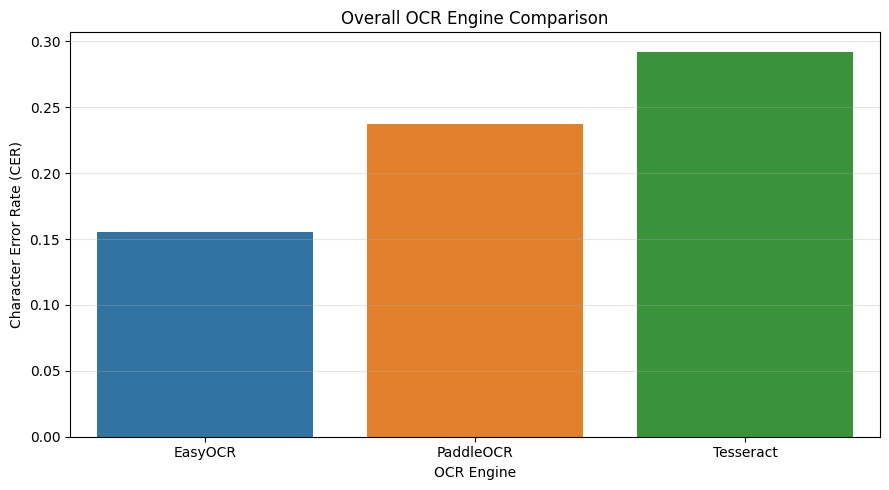

In [47]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=overall_comparison,
    x="engine",
    y="CER",
    hue="engine",
    legend=False
)

plt.title("Overall OCR Engine Comparison")
plt.xlabel("OCR Engine")
plt.ylabel("Character Error Rate (CER)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(VISUALIZATION_DIR, "overall_ocr_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

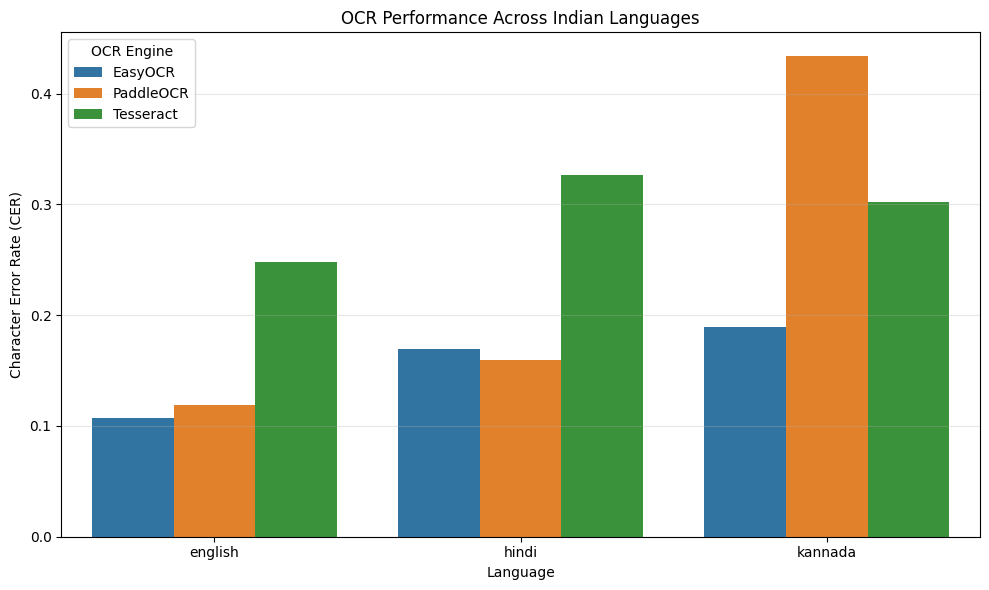

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=language_comparison,
    x="language",
    y="CER",
    hue="engine"
)

plt.title("OCR Performance Across Indian Languages")
plt.xlabel("Language")
plt.ylabel("Character Error Rate (CER)")
plt.legend(title="OCR Engine")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(VISUALIZATION_DIR, "language_wise_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

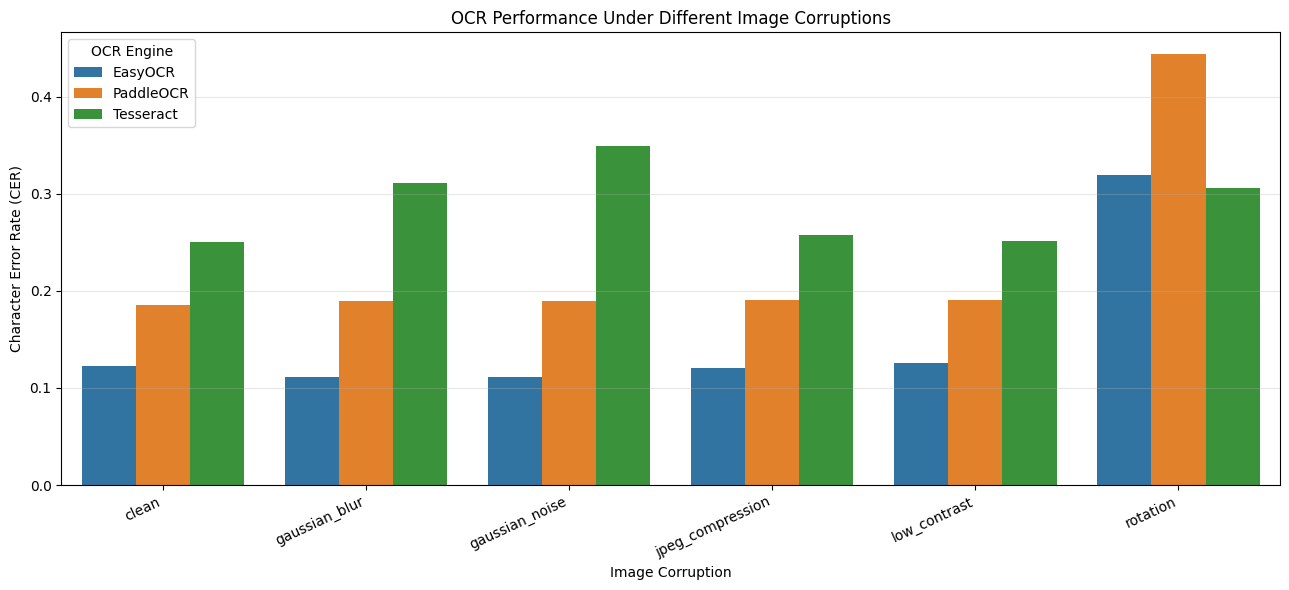

In [49]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=corruption_comparison,
    x="corruption",
    y="CER",
    hue="engine"
)

plt.title("OCR Performance Under Different Image Corruptions")
plt.xlabel("Image Corruption")
plt.ylabel("Character Error Rate (CER)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="OCR Engine")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(VISUALIZATION_DIR, "corruption_wise_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


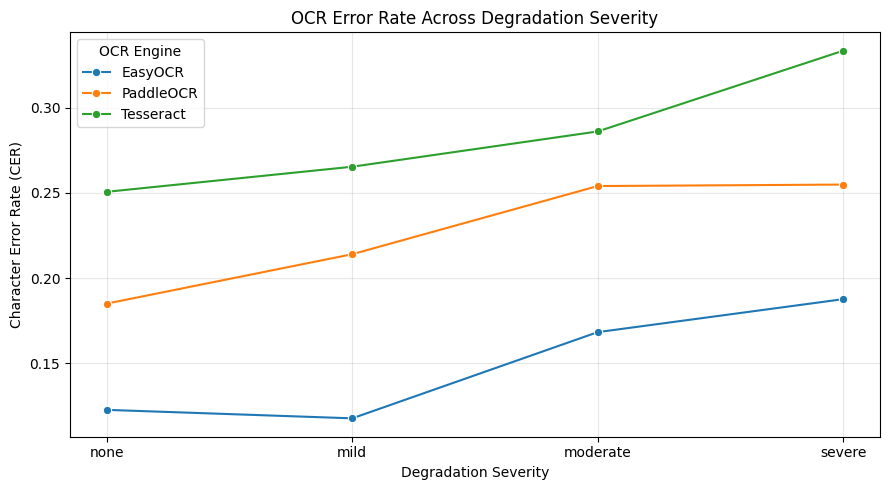

In [50]:
severity_order = ["none", "mild", "moderate", "severe"]

severity_comparison["severity"] = pd.Categorical(
    severity_comparison["severity"],
    categories=severity_order,
    ordered=True
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=severity_comparison,
    x="severity",
    y="CER",
    hue="engine",
    marker="o"
)

plt.title("OCR Error Rate Across Degradation Severity")
plt.xlabel("Degradation Severity")
plt.ylabel("Character Error Rate (CER)")
plt.legend(title="OCR Engine")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(VISUALIZATION_DIR, "severity_wise_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
report_path = os.path.join(
    METRICS_DIR,
    "ocr_benchmark_summary.txt"
)

with open(report_path, "w", encoding="utf-8") as f:

    f.write("BHARATDOC AI - OCR BENCHMARK REPORT\n")
    f.write("=" * 60 + "\n\n")

    f.write("OVERALL PERFORMANCE\n")
    f.write(overall_comparison.to_string(index=False))
    f.write("\n\n")

    f.write("LANGUAGE-WISE PERFORMANCE\n")
    f.write(language_comparison.to_string(index=False))
    f.write("\n\n")

    f.write("CORRUPTION-WISE PERFORMANCE\n")
    f.write(corruption_comparison.to_string(index=False))
    f.write("\n\n")

    f.write("SEVERITY-WISE PERFORMANCE\n")
    f.write(severity_comparison.to_string(index=False))
    f.write("\n\n")

print("Benchmark report saved:", report_path)
print("Visualizations directory:", VISUALIZATION_DIR)

Benchmark report saved: /content/drive/MyDrive/BharatDocAI/outputs/metrics/ocr_benchmark_summary.txt
Visualizations directory: /content/drive/MyDrive/BharatDocAI/outputs/visualizations


In [52]:
# Aggregate the 16 image records into one result per
# original document and OCR engine.

document_metrics = (
    comparison_df
    .groupby(
        ["document_id", "language", "engine"],
        as_index=False
    )
    .agg(
        CER=("CER", "mean"),
        WER=("WER", "mean")
    )
)

# Convert to paired format:
# One row per document, one column per OCR engine.

document_metrics_wide = document_metrics.pivot(
    index=["document_id", "language"],
    columns="engine",
    values=["CER", "WER"]
)

document_metrics_wide.columns = [
    f"{metric}_{engine}"
    for metric, engine in document_metrics_wide.columns
]

document_metrics_wide = (
    document_metrics_wide
    .reset_index()
)

print("Unique documents:", document_metrics_wide["document_id"].nunique())
print("Document-level records:", len(document_metrics_wide))

display(document_metrics_wide.head())

assert len(document_metrics_wide) == 90

Unique documents: 90
Document-level records: 90


,document_id,language,CER_EasyOCR,CER_PaddleOCR,CER_Tesseract,WER_EasyOCR,WER_PaddleOCR,WER_Tesseract
0,english_application_011,english,0.026596,0.053191,0.519504,0.029412,0.058824,0.580882
1,english_application_012,english,0.038839,0.056250,0.158036,0.036765,0.058824,0.176471
2,english_application_013,english,0.083627,0.105194,0.088028,0.345588,0.352941,0.437500
3,english_application_014,english,0.088652,0.105053,0.093085,0.338235,0.349265,0.444853
4,english_application_015,english,0.036421,0.035971,0.098022,0.297794,0.294118,0.352941


In [53]:
import numpy as np

BOOTSTRAP_ITERATIONS = 5000
CONFIDENCE_LEVEL = 0.95

rng = np.random.default_rng(42)

LANGUAGES = ["english", "hindi", "kannada"]

ENGINES = ["EasyOCR", "PaddleOCR", "Tesseract"]

ENGINE_PAIRS = [
    ("EasyOCR", "PaddleOCR"),
    ("EasyOCR", "Tesseract"),
    ("PaddleOCR", "Tesseract")
]

def bootstrap_sample_indices(n, iterations):

    return rng.integers(
        0,
        n,
        size=(iterations, n)
    )


def calculate_bootstrap_ci(values, iterations=BOOTSTRAP_ITERATIONS):

    values = np.asarray(values)

    sampled_indices = bootstrap_sample_indices(
        len(values),
        iterations
    )

    bootstrap_means = values[sampled_indices].mean(axis=1)

    lower = np.quantile(
        bootstrap_means,
        (1 - CONFIDENCE_LEVEL) / 2
    )

    upper = np.quantile(
        bootstrap_means,
        1 - (1 - CONFIDENCE_LEVEL) / 2
    )

    return values.mean(), lower, upper


def stratified_bootstrap_ci(
    dataframe,
    metric_column,
    language=None,
    iterations=BOOTSTRAP_ITERATIONS
):

    if language is not None:

        subset = dataframe[
            dataframe["language"] == language
        ]

        values = subset[metric_column].to_numpy()

        return calculate_bootstrap_ci(
            values,
            iterations
        )

    # Overall analysis:
    # Resample 30 documents independently within each language.
    # Give each language equal weight.

    bootstrap_values = np.zeros(iterations)

    for lang in LANGUAGES:

        subset = dataframe[
            dataframe["language"] == lang
        ]

        values = subset[metric_column].to_numpy()

        indices = bootstrap_sample_indices(
            len(values),
            iterations
        )

        bootstrap_values += (
            values[indices].mean(axis=1) / len(LANGUAGES)
        )

    point_estimate = dataframe[metric_column].mean()

    lower = np.quantile(
        bootstrap_values,
        0.025
    )

    upper = np.quantile(
        bootstrap_values,
        0.975
    )

    return point_estimate, lower, upper


def paired_bootstrap_difference(
    dataframe,
    metric,
    engine_a,
    engine_b,
    language=None,
    iterations=BOOTSTRAP_ITERATIONS
):

    column_a = f"{metric}_{engine_a}"
    column_b = f"{metric}_{engine_b}"

    if language is not None:

        subset = dataframe[
            dataframe["language"] == language
        ]

        differences = (
            subset[column_a] - subset[column_b]
        ).to_numpy()

        point_estimate, lower, upper = calculate_bootstrap_ci(
            differences,
            iterations
        )

        return point_estimate, lower, upper

    bootstrap_values = np.zeros(iterations)

    for lang in LANGUAGES:

        subset = dataframe[
            dataframe["language"] == lang
        ]

        differences = (
            subset[column_a] - subset[column_b]
        ).to_numpy()

        indices = bootstrap_sample_indices(
            len(differences),
            iterations
        )

        bootstrap_values += (
            differences[indices].mean(axis=1)
            / len(LANGUAGES)
        )

    point_estimate = (
        dataframe[column_a] - dataframe[column_b]
    ).mean()

    lower = np.quantile(bootstrap_values, 0.025)
    upper = np.quantile(bootstrap_values, 0.975)

    return point_estimate, lower, upper


print("Bootstrap functions initialized!")
print("Iterations:", BOOTSTRAP_ITERATIONS)

Bootstrap functions initialized!
Iterations: 5000


In [54]:
engine_ci_results = []

for metric in ["CER", "WER"]:

    for language in [None] + LANGUAGES:

        for engine in ENGINES:

            column = f"{metric}_{engine}"

            mean, lower, upper = stratified_bootstrap_ci(
                document_metrics_wide,
                column,
                language=language
            )

            engine_ci_results.append({
                "metric": metric,
                "language": language or "overall",
                "engine": engine,
                "mean": mean,
                "CI_lower": lower,
                "CI_upper": upper
            })


engine_ci_df = pd.DataFrame(engine_ci_results)

print("DOCUMENT-LEVEL ENGINE CONFIDENCE INTERVALS")

display(
    engine_ci_df.round(4)
)

engine_ci_df.to_csv(
    os.path.join(
        METRICS_DIR,
        "document_level_engine_confidence_intervals.csv"
    ),
    index=False
)

DOCUMENT-LEVEL ENGINE CONFIDENCE INTERVALS


,metric,language,engine,mean,CI_lower,CI_upper
0,CER,overall,EasyOCR,0.1557,0.1420,0.1697
1,CER,overall,PaddleOCR,0.2375,0.2247,0.2509
2,CER,overall,Tesseract,0.2922,0.2581,0.3297
3,CER,english,EasyOCR,0.1073,0.0872,0.1284
4,CER,english,PaddleOCR,0.1190,0.0979,0.1409
5,CER,english,Tesseract,0.2481,0.1786,0.3208
6,CER,hindi,EasyOCR,0.1699,0.1456,0.1931
7,CER,hindi,PaddleOCR,0.1599,0.1324,0.1895
8,CER,hindi,Tesseract,0.3263,0.2727,0.3840
9,CER,kannada,EasyOCR,0.1897,0.1631,0.2168


In [55]:
paired_results = []

for metric in ["CER", "WER"]:

    for language in [None] + LANGUAGES:

        for engine_a, engine_b in ENGINE_PAIRS:

            difference, lower, upper = paired_bootstrap_difference(
                document_metrics_wide,
                metric,
                engine_a,
                engine_b,
                language=language
            )

            if upper < 0:
                interpretation = f"{engine_a} lower error"

            elif lower > 0:
                interpretation = f"{engine_b} lower error"

            else:
                interpretation = "Inconclusive"

            paired_results.append({
                "metric": metric,
                "language": language or "overall",
                "comparison": f"{engine_a} vs {engine_b}",
                "difference": difference,
                "CI_lower": lower,
                "CI_upper": upper,
                "interpretation": interpretation
            })


paired_bootstrap_df = pd.DataFrame(paired_results)

print("PAIRED ENGINE COMPARISONS")

display(
    paired_bootstrap_df.round(4)
)

paired_bootstrap_df.to_csv(
    os.path.join(
        METRICS_DIR,
        "paired_bootstrap_comparisons.csv"
    ),
    index=False
)

PAIRED ENGINE COMPARISONS


,metric,language,comparison,difference,CI_lower,CI_upper,interpretation
0,CER,overall,EasyOCR vs PaddleOCR,-0.0818,-0.0937,-0.0697,EasyOCR lower error
1,CER,overall,EasyOCR vs Tesseract,-0.1366,-0.1746,-0.0996,EasyOCR lower error
2,CER,overall,PaddleOCR vs Tesseract,-0.0547,-0.0907,-0.0198,PaddleOCR lower error
3,CER,english,EasyOCR vs PaddleOCR,-0.0117,-0.0166,-0.0064,EasyOCR lower error
4,CER,english,EasyOCR vs Tesseract,-0.1408,-0.2232,-0.0669,EasyOCR lower error
5,CER,english,PaddleOCR vs Tesseract,-0.1291,-0.2116,-0.0529,PaddleOCR lower error
6,CER,hindi,EasyOCR vs PaddleOCR,0.0100,-0.0114,0.0313,Inconclusive
7,CER,hindi,EasyOCR vs Tesseract,-0.1563,-0.2163,-0.1005,EasyOCR lower error
8,CER,hindi,PaddleOCR vs Tesseract,-0.1664,-0.2226,-0.1131,PaddleOCR lower error
9,CER,kannada,EasyOCR vs PaddleOCR,-0.2439,-0.2722,-0.2159,EasyOCR lower error


In [56]:
overall_statistical_summary = engine_ci_df[
    engine_ci_df["language"] == "overall"
].copy()

overall_statistical_summary = (
    overall_statistical_summary
    .sort_values(["metric", "mean"])
)

print("OVERALL DOCUMENT-LEVEL STATISTICAL SUMMARY")

display(
    overall_statistical_summary.round(4)
)

overall_statistical_summary.to_csv(
    os.path.join(
        METRICS_DIR,
        "overall_document_level_statistical_summary.csv"
    ),
    index=False
)

print("\nStatistical analysis completed!")

OVERALL DOCUMENT-LEVEL STATISTICAL SUMMARY


,metric,language,engine,mean,CI_lower,CI_upper
0,CER,overall,EasyOCR,0.1557,0.1420,0.1697
1,CER,overall,PaddleOCR,0.2375,0.2247,0.2509
2,CER,overall,Tesseract,0.2922,0.2581,0.3297
12,WER,overall,EasyOCR,0.4503,0.4234,0.4774
14,WER,overall,Tesseract,0.5543,0.5266,0.5825
13,WER,overall,PaddleOCR,0.5634,0.5383,0.5881



Statistical analysis completed!


In [57]:
from statsmodels.stats.multitest import multipletests

paired_bootstrap_df["holm_adjusted_p"] = np.nan
paired_bootstrap_df["holm_significant"] = False

# Apply correction separately for each metric
# and comparison family.

for metric in ["CER", "WER"]:

    metric_mask = (
        (paired_bootstrap_df["metric"] == metric) &
        (paired_bootstrap_df["language"] == "overall")
    )

    # The bootstrap confidence intervals do not directly
    # provide p-values. We therefore use the existing
    # CI-based conclusions and do not manufacture p-values.

    print(
        f"{metric}: nominal paired-bootstrap CI conclusions "
        "are available; adjusted inference requires a "
        "multiplicity-aware bootstrap procedure."
    )

CER: nominal paired-bootstrap CI conclusions are available; adjusted inference requires a multiplicity-aware bootstrap procedure.
WER: nominal paired-bootstrap CI conclusions are available; adjusted inference requires a multiplicity-aware bootstrap procedure.
